# 12 — Proposed Hierarchical DINOv2 + Attention MIL

**Purpose:** combine the learned slice-attention mechanism from Notebook 10 with the learned series-attention mechanism from Notebook 11.

**Architecture:** frozen DINOv2 2.5D embeddings → gated slice attention within each MRI series → gated series attention within each study → 12 study-level sigmoid outputs.

**Protocol:** 58 complete gold-labelled studies; unchanged five study-level folds from Notebook 05/09; inner split for epoch selection; reinitialize and refit on the full outer-training fold; evaluate the untouched outer fold; fixed threshold 0.50.

This is the **gold-only hierarchical baseline**. It does not use report text or pseudo-labels; confidence-weighted report supervision belongs in Notebook 13.

**Inputs:** RSNA competition dataset and Notebook 09,10,11 output through Kaggle Add Input

In [1]:
import os, gc, json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score,
    recall_score, hamming_loss, accuracy_score
)

warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 5
EXPECTED_GOLD_STUDIES = 58
EMBED_DIM = 384
NUM_CLASSES = 12
CLASSIFICATION_THRESHOLD = 0.50

# Match the settings used by Notebooks 10 and 11.
EPOCHS = 50
PATIENCE = 10
ATTENTION_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_GRAD_NORM = 1.0
POS_WEIGHT_MAX = 20.0

OUTPUT_DIR = "/kaggle/working/12_proposed_model"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LABEL_COLS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
if torch.get_num_threads() > 4:
    torch.set_num_threads(4)

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Output:", OUTPUT_DIR)
print("Labels:", len(LABEL_COLS))

Device: cpu
GPU: Not available
Output: /kaggle/working/12_proposed_model
Labels: 12


## 2. Locate the competition data and Notebook 09 embeddings

The notebook discovers files by exact filename under `/kaggle/input`. Attach the Notebook 09 output and RSNA competition dataset before running.

In [2]:
SEARCH_ROOTS = ["/kaggle/input", "/kaggle/working"]
PRUNE_DIRS = {
    "train_images", "test_images", "train_series", "test_series",
    "processed_data", "__pycache__", ".git", ".ipynb_checkpoints"
}

def find_files(filename):
    found = []
    for root in SEARCH_ROOTS:
        if not os.path.exists(root):
            continue
        for current, dirs, files in os.walk(root):
            dirs[:] = [d for d in dirs if d not in PRUNE_DIRS]
            if filename in files:
                found.append(os.path.join(current, filename))
    return sorted(set(found))

def choose_file(filename, preferred_tokens=(), required=True):
    paths = find_files(filename)
    if not paths:
        if required:
            raise FileNotFoundError(
                f"Cannot find {filename}. Attach the RSNA competition dataset "
                "and Notebook 09 output using Kaggle Add Input."
            )
        return None
    for token in preferred_tokens:
        preferred = [p for p in paths if token.lower() in p.lower()]
        if preferred:
            paths = preferred
            break
    if len(paths) > 1:
        print(f"Multiple copies of {filename}; using: {paths[0]}")
        for p in paths[:8]:
            print("  ", p)
    return paths[0]

TRAIN_CSV_PATH = choose_file(
    "train.csv",
    ("competitions/rsna", "rsna-knee-abnormality-detection", "rsna-knee")
)
EMBEDDING_PATH = choose_file(
    "dinov2_vits14_embeddings_float16.npy", ("09-dinov2", "dinov2")
)
METADATA_PATH = choose_file(
    "dinov2_vits14_embedding_metadata.csv", ("09-dinov2", "dinov2")
)
MANIFEST_PATH = choose_file(
    "dinov2_vits14_embedding_manifest.json", ("09-dinov2", "dinov2"), required=False
)

print("train.csv:", TRAIN_CSV_PATH)
print("Embeddings:", EMBEDDING_PATH)
print("Metadata:", METADATA_PATH)
print("Manifest:", MANIFEST_PATH or "not attached (optional)")

train.csv: /kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv
Embeddings: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embeddings_float16.npy
Metadata: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_metadata.csv
Manifest: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_manifest.json


## 3. Load and validate gold labels, embeddings and original folds

The fold assignments are read from Notebook 09 metadata; this notebook does not create new folds. Every study must have exactly one fold, and all 58 fully labelled studies must be represented.

In [3]:
if MANIFEST_PATH:
    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        manifest = json.load(f)
    if manifest.get("smoke_test") is True:
        raise RuntimeError("Notebook 09 output is marked smoke_test=True; attach the full gold output.")
    if manifest.get("data_scope", "gold") != "gold":
        raise RuntimeError("Notebook 12 requires Notebook 09 DATA_SCOPE='gold'.")
    if manifest.get("embedding_dim", EMBED_DIM) != EMBED_DIM:
        raise RuntimeError("Unexpected embedding dimension in Notebook 09 manifest.")
else:
    manifest = {}

train = pd.read_csv(TRAIN_CSV_PATH)
metadata = pd.read_csv(METADATA_PATH)
emb_memmap = np.load(EMBEDDING_PATH, mmap_mode="r")

required_meta = ["Embedding_Index", "StudyInstanceUID", "SeriesInstanceUID", "fold"]
missing = [c for c in required_meta if c not in metadata.columns]
if missing:
    raise ValueError(f"Notebook 09 metadata missing columns: {missing}")
missing_labels = [c for c in ["StudyInstanceUID"] + LABEL_COLS if c not in train.columns]
if missing_labels:
    raise ValueError(f"train.csv missing columns: {missing_labels}")
if emb_memmap.ndim != 2 or emb_memmap.shape[1] != EMBED_DIM:
    raise ValueError(f"Expected embeddings [N,{EMBED_DIM}], got {emb_memmap.shape}.")
if len(metadata) != len(emb_memmap):
    raise ValueError("Embedding and metadata row counts differ.")

metadata["Embedding_Index"] = pd.to_numeric(metadata["Embedding_Index"], errors="raise").astype(int)
metadata["fold"] = pd.to_numeric(metadata["fold"], errors="raise").astype(int)
metadata["StudyInstanceUID"] = metadata["StudyInstanceUID"].astype(str)
metadata["SeriesInstanceUID"] = metadata["SeriesInstanceUID"].astype(str)
metadata = metadata.sort_values("Embedding_Index").reset_index(drop=True)

expected_idx = np.arange(len(metadata))
if not np.array_equal(metadata["Embedding_Index"].to_numpy(), expected_idx):
    raise ValueError("Embedding_Index must be unique and contiguous from 0 to N-1.")
if metadata["Embedding_Index"].duplicated().any():
    raise ValueError("Duplicate Embedding_Index values.")
embeddings = np.asarray(emb_memmap, dtype=np.float32)
del emb_memmap
if not np.isfinite(embeddings).all():
    raise ValueError("Non-finite DINOv2 embeddings detected.")

train["StudyInstanceUID"] = train["StudyInstanceUID"].astype(str)
for col in LABEL_COLS:
    train[col] = pd.to_numeric(train[col], errors="coerce")
gold = train.dropna(subset=LABEL_COLS).copy()
if gold["StudyInstanceUID"].duplicated().any():
    raise ValueError("Duplicate gold StudyInstanceUID rows in train.csv.")

fold_counts_per_study = metadata.groupby("StudyInstanceUID")["fold"].nunique()
if not (fold_counts_per_study == 1).all():
    raise ValueError("At least one study has multiple fold assignments.")
fold_map = metadata[["StudyInstanceUID", "fold"]].drop_duplicates()
gold = gold.merge(fold_map, on="StudyInstanceUID", how="inner", validate="one_to_one")

meta_studies = set(metadata["StudyInstanceUID"])
gold_studies = set(gold["StudyInstanceUID"])
if meta_studies != gold_studies:
    raise ValueError(
        f"Gold/embedding coverage mismatch: missing={len(gold_studies-meta_studies)}, "
        f"extra={len(meta_studies-gold_studies)}."
    )
if len(gold) != EXPECTED_GOLD_STUDIES:
    raise ValueError(f"Expected 58 gold studies, found {len(gold)}.")
if set(gold["fold"].unique()) != set(range(N_FOLDS)):
    raise ValueError(f"Expected folds 0..4, got {sorted(gold['fold'].unique())}.")
if not gold[LABEL_COLS].isin([0, 1]).all().all():
    raise ValueError("Gold labels must be binary 0/1.")
expected_fold_sizes = np.array([12, 12, 12, 11, 11])
actual_fold_sizes = gold["fold"].value_counts().sort_index().to_numpy()
if not np.array_equal(actual_fold_sizes, expected_fold_sizes):
    raise ValueError(f"Unexpected fold sizes: {actual_fold_sizes}.")

gold = gold.sort_values(["fold", "StudyInstanceUID"]).reset_index(drop=True)
LABEL_BY_STUDY = {
    r["StudyInstanceUID"]: r[LABEL_COLS].to_numpy(dtype=np.float32)
    for _, r in gold.iterrows()
}
FOLD_BY_STUDY = dict(zip(gold["StudyInstanceUID"], gold["fold"].astype(int)))
STUDY_IDS = sorted(gold["StudyInstanceUID"].tolist())

print("Embedding shape:", embeddings.shape)
print("Metadata rows:", len(metadata))
print("Gold studies:", len(STUDY_IDS))
print("Fold counts:", gold["fold"].value_counts().sort_index().to_dict())
print("Gold-label / embedding / fold integrity: PASSED")

Embedding shape: (10528, 384)
Metadata rows: 10528
Gold studies: 58
Fold counts: {0: 12, 1: 12, 2: 12, 3: 11, 4: 11}
Gold-label / embedding / fold integrity: PASSED


## 4. Build nested study → series → 2.5D-instance bags

Unlike Notebook 10's flat study bag or Notebook 11's mean-pooled series vectors, this notebook preserves the full hierarchy. Each MRI series contains its original DINOv2 instance embeddings.

In [4]:
OPTIONAL_META = [
    "Anatomical_Plane", "Fluid_Sensitive", "Fat_Suppression",
    "Num_Slices", "Prev_Slice_Index", "Center_Slice_Index", "Next_Slice_Index"
]

STUDY_BAGS = {}
for study_id, study_group in metadata.groupby("StudyInstanceUID", sort=True):
    series_bags = []
    for series_id, series_group in study_group.groupby("SeriesInstanceUID", sort=True):
        series_group = series_group.sort_values("Embedding_Index")
        idx = series_group["Embedding_Index"].to_numpy(dtype=np.int64)
        if len(idx) == 0:
            raise RuntimeError(f"Empty series: {study_id} / {series_id}")
        rec = {
            "StudyInstanceUID": str(study_id),
            "SeriesInstanceUID": str(series_id),
            "fold": int(series_group["fold"].iloc[0]),
            "embedding_indices": idx,
            "Num_2p5D_Instances": int(len(idx)),
        }
        for col in OPTIONAL_META:
            if col in series_group.columns:
                vals = series_group[col].dropna()
                rec[col] = vals.iloc[0] if len(vals) else np.nan
        series_bags.append(rec)
    if not series_bags:
        raise RuntimeError(f"Study has no MRI series: {study_id}")
    STUDY_BAGS[str(study_id)] = series_bags

if set(STUDY_BAGS) != set(STUDY_IDS):
    raise RuntimeError("Nested study bags do not cover exactly the gold studies.")

total_series = sum(len(v) for v in STUDY_BAGS.values())
total_instances = sum(
    len(s["embedding_indices"]) for bag in STUDY_BAGS.values() for s in bag
)
if total_instances != len(metadata):
    raise RuntimeError("Nested bags do not account for every embedding row.")

print("Studies:", len(STUDY_BAGS))
print("MRI series:", total_series)
print("2.5D instances:", total_instances)
print("Embedding dimension:", embeddings.shape[1])
print("Series per study:")
display(pd.Series({k: len(v) for k, v in STUDY_BAGS.items()}).describe().to_frame("series_count"))

Studies: 58
MRI series: 336
2.5D instances: 10528
Embedding dimension: 384
Series per study:


,series_count
count,58.000000
mean,5.793103
std,1.460096
min,4.000000
25%,5.000000
50%,5.000000
75%,6.000000
max,9.000000


## 5. Define the hierarchical gated-attention model

The slice-attention block follows Notebook 10's gated attention (`tanh(Vx) × sigmoid(Ux)` → softmax). The series-attention block follows Notebook 11's same gated-attention formulation, now operating on learned series representations. The classifier emits 12 logits; sigmoid probabilities are used for evaluation.

In [5]:
class GatedAttentionPool(nn.Module):
    def __init__(self, input_dim, attention_dim):
        super().__init__()
        self.norm = nn.LayerNorm(input_dim)
        self.attention_v = nn.Linear(input_dim, attention_dim)
        self.attention_u = nn.Linear(input_dim, attention_dim)
        self.attention_w = nn.Linear(attention_dim, 1, bias=False)

    def forward(self, instances):
        if instances.ndim != 2 or instances.shape[0] == 0:
            raise ValueError("Attention expects a non-empty [instances, features] tensor.")
        x = self.norm(instances)
        gated = torch.tanh(self.attention_v(x)) * torch.sigmoid(self.attention_u(x))
        weights = torch.softmax(self.attention_w(gated).squeeze(-1), dim=0)
        pooled = torch.sum(weights.unsqueeze(-1) * x, dim=0)
        return pooled, weights


class HierarchicalDINOv2MIL(nn.Module):
    def __init__(self, input_dim=EMBED_DIM, attention_dim=ATTENTION_DIM,
                 hidden_dim=HIDDEN_DIM, num_classes=NUM_CLASSES, dropout=DROPOUT):
        super().__init__()
        self.slice_attention = GatedAttentionPool(input_dim, attention_dim)
        self.series_attention = GatedAttentionPool(input_dim, attention_dim)
        self.classifier = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, series_bags, return_attention=False):
        if not series_bags:
            raise ValueError("A study must contain at least one MRI series.")
        series_vectors, slice_weights_all = [], []
        for instance_embeddings in series_bags:
            pooled_series, slice_weights = self.slice_attention(instance_embeddings)
            series_vectors.append(pooled_series)
            slice_weights_all.append(slice_weights)
        series_matrix = torch.stack(series_vectors, dim=0)
        study_embedding, series_weights = self.series_attention(series_matrix)
        logits = self.classifier(study_embedding)
        if return_attention:
            return logits, slice_weights_all, series_weights
        return logits


def get_study_tensors(study_id):
    return [
        torch.as_tensor(embeddings[s["embedding_indices"]], dtype=torch.float32, device=DEVICE)
        for s in STUDY_BAGS[study_id]
    ]


def create_pos_weight(study_ids):
    y = np.stack([LABEL_BY_STUDY[s] for s in study_ids]).astype(np.float32)
    positives = y.sum(axis=0)
    negatives = len(y) - positives
    weights = np.ones(NUM_CLASSES, dtype=np.float32)
    valid = positives > 0
    weights[valid] = negatives[valid] / positives[valid]
    weights = np.clip(weights, 1.0, POS_WEIGHT_MAX)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


model = HierarchicalDINOv2MIL().to(DEVICE)
sample_id = STUDY_IDS[0]
with torch.no_grad():
    logits, slice_w, series_w = model(get_study_tensors(sample_id), return_attention=True)
assert logits.shape == (NUM_CLASSES,)
assert len(slice_w) == len(STUDY_BAGS[sample_id])
assert torch.isfinite(logits).all()
assert torch.allclose(series_w.sum(), torch.tensor(1.0, device=DEVICE), atol=1e-6)
assert all(torch.allclose(w.sum(), torch.tensor(1.0, device=DEVICE), atol=1e-6) for w in slice_w)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Smoke test: logits", tuple(logits.shape), "| series attention", tuple(series_w.shape), "| slice groups", len(slice_w))
del model, logits, slice_w, series_w

HierarchicalDINOv2MIL(
  (slice_attention): GatedAttentionPool(
    (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    (attention_v): Linear(in_features=384, out_features=128, bias=True)
    (attention_u): Linear(in_features=384, out_features=128, bias=True)
    (attention_w): Linear(in_features=128, out_features=1, bias=False)
  )
  (series_attention): GatedAttentionPool(
    (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    (attention_v): Linear(in_features=384, out_features=128, bias=True)
    (attention_u): Linear(in_features=384, out_features=128, bias=True)
    (attention_w): Linear(in_features=128, out_features=1, bias=False)
  )
  (classifier): Sequential(
    (0): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=384, out_features=128, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=12, bias=True)
  )
)
Trainable parameters: 250508
S

## 6. Metrics and evaluation helpers

Epoch selection uses only an inner validation subset drawn from the outer-training studies. The outer held-out fold is evaluated only after reinitializing and refitting the model on the complete outer-training fold.

In [6]:
def per_class_metrics(y_true, y_prob, threshold=CLASSIFICATION_THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    rows = []
    for j, label in enumerate(LABEL_COLS):
        yt, yp, pred = y_true[:, j], y_prob[:, j], y_pred[:, j]
        tp = int(((yt == 1) & (pred == 1)).sum())
        tn = int(((yt == 0) & (pred == 0)).sum())
        fp = int(((yt == 0) & (pred == 1)).sum())
        fn = int(((yt == 1) & (pred == 0)).sum())
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall = tp / (tp + fn) if tp + fn else np.nan
        specificity = tn / (tn + fp) if tn + fp else np.nan
        f1 = (2 * precision * recall / (precision + recall)
              if np.isfinite(precision) and np.isfinite(recall) and precision + recall > 0 else 0.0)
        auc = roc_auc_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan
        ap = average_precision_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan
        rows.append({
            "label": label, "positive_count": int(yt.sum()),
            "precision": precision, "recall": recall, "sensitivity": recall,
            "specificity": specificity, "f1": f1, "roc_auc": auc, "pr_auc": ap,
            "tp": tp, "tn": tn, "fp": fp, "fn": fn
        })
    return pd.DataFrame(rows)


def calculate_metrics(y_true, y_prob, threshold=CLASSIFICATION_THRESHOLD):
    pc = per_class_metrics(y_true, y_prob, threshold)
    yp = (np.asarray(y_prob) >= threshold).astype(int)
    valid_auc = pc["roc_auc"].dropna()
    valid_ap = pc["pr_auc"].dropna()
    return {
        "macro_auc": float(valid_auc.mean()) if len(valid_auc) else np.nan,
        "macro_pr_auc": float(valid_ap.mean()) if len(valid_ap) else np.nan,
        "macro_precision": float(precision_score(y_true, yp, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, yp, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, yp, average="macro", zero_division=0)),
        "macro_specificity": float(pc["specificity"].mean()),
        "micro_f1": float(f1_score(y_true, yp, average="micro", zero_division=0)),
        "hamming_loss": float(hamming_loss(y_true, yp)),
        "subset_accuracy": float(accuracy_score(y_true, yp)),
        "valid_auc_classes": int(len(valid_auc)),
        "valid_pr_auc_classes": int(len(valid_ap)),
    }


def evaluate_studies(model, study_ids, criterion, fold, collect_attention=False):
    model.eval()
    losses, truths, probabilities = [], [], []
    slice_records, series_records = [], []
    with torch.no_grad():
        for study_id in study_ids:
            bags = get_study_tensors(study_id)
            y_np = LABEL_BY_STUDY[study_id]
            y = torch.as_tensor(y_np, dtype=torch.float32, device=DEVICE)
            if collect_attention:
                logits, slice_weights, series_weights = model(bags, return_attention=True)
                for s_idx, (series_info, weights) in enumerate(zip(STUDY_BAGS[study_id], slice_weights)):
                    weights_np = weights.detach().cpu().numpy()
                    for local_i, weight in enumerate(weights_np):
                        emb_idx = int(series_info["embedding_indices"][local_i])
                        meta_row = metadata.iloc[emb_idx].to_dict()
                        meta_row["fold"] = int(fold)
                        meta_row["slice_attention_weight"] = float(weight)
                        slice_records.append(meta_row)
                for s_idx, (series_info, weight) in enumerate(zip(STUDY_BAGS[study_id], series_weights.detach().cpu().numpy())):
                    row = {k: v for k, v in series_info.items() if k != "embedding_indices"}
                    row["fold"] = int(fold)
                    row["series_attention_weight"] = float(weight)
                    series_records.append(row)
            else:
                logits = model(bags)
            loss = criterion(logits.unsqueeze(0), y.unsqueeze(0))
            losses.append(float(loss.item()))
            truths.append(y_np)
            probabilities.append(torch.sigmoid(logits).detach().cpu().numpy())
    return {
        "loss": float(np.mean(losses)),
        "y_true": np.stack(truths),
        "y_prob": np.stack(probabilities),
        "slice_records": slice_records,
        "series_records": series_records,
    }

print("Evaluation helpers ready.")

Evaluation helpers ready.


## 7. Five-fold training: inner epoch selection, outer refit and OOF evaluation

This is the main experiment. It saves each fold checkpoint and partial results immediately after that fold completes, so a later interruption does not erase completed-fold artifacts.

In [7]:
def train_epoch(model, study_ids, criterion, optimizer, fold, epoch, seed_offset):
    model.train()
    rng = np.random.RandomState(SEED + int(fold) * 10000 + seed_offset + epoch)
    losses = []
    for study_id in rng.permutation(np.asarray(study_ids, dtype=object)):
        bags = get_study_tensors(str(study_id))
        y = torch.as_tensor(LABEL_BY_STUDY[str(study_id)], dtype=torch.float32, device=DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(bags)
        loss = criterion(logits.unsqueeze(0), y.unsqueeze(0))
        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss: fold={fold}, epoch={epoch}")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        optimizer.step()
        losses.append(float(loss.item()))
    return float(np.mean(losses))


def train_one_fold(fold):
    outer_train = sorted(s for s in STUDY_IDS if FOLD_BY_STUDY[s] != fold)
    outer_val = sorted(s for s in STUDY_IDS if FOLD_BY_STUDY[s] == fold)
    rng = np.random.RandomState(SEED + 1000 + int(fold))
    shuffled = list(rng.permutation(np.asarray(outer_train, dtype=object)))
    n_inner_val = max(1, int(round(0.20 * len(shuffled))))
    inner_val = sorted(map(str, shuffled[:n_inner_val]))
    inner_train = sorted(map(str, shuffled[n_inner_val:]))
    if not inner_train or not inner_val or not outer_val:
        raise RuntimeError(f"Invalid split in fold {fold}")

    def new_model():
        return HierarchicalDINOv2MIL().to(DEVICE)

    set_seed(SEED + int(fold))
    selection_model = new_model()
    selection_loss = nn.BCEWithLogitsLoss(pos_weight=create_pos_weight(inner_train))
    selection_opt = torch.optim.AdamW(
        selection_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )

    best_loss, best_epoch, patience_count = np.inf, 0, 0
    history = []
    print(f"\nFOLD {fold}: outer train={len(outer_train)}, held-out={len(outer_val)}; "
          f"inner train={len(inner_train)}, inner val={len(inner_val)}")

    for epoch in range(1, EPOCHS + 1):
        tr_loss = train_epoch(selection_model, inner_train, selection_loss, selection_opt, fold, epoch, 0)
        val_out = evaluate_studies(selection_model, inner_val, selection_loss, fold, False)
        val_loss = val_out["loss"]
        history.append({
            "fold": fold, "epoch": epoch, "train_loss": tr_loss,
            "val_loss": val_loss, "stage": "inner_epoch_selection"
        })
        print(f"Fold {fold} | epoch {epoch:02d} | train={tr_loss:.4f} | inner-val={val_loss:.4f}")
        if val_loss < best_loss - 1e-6:
            best_loss, best_epoch, patience_count = val_loss, epoch, 0
        else:
            patience_count += 1
        if patience_count >= PATIENCE:
            print("Early stopping")
            break

    del selection_model, selection_opt, selection_loss
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if best_epoch == 0:
        raise RuntimeError(f"No valid epoch selected for fold {fold}")

    # Reinitialize and refit on the complete outer-training fold.
    set_seed(SEED + 10000 + int(fold))
    final_model = new_model()
    outer_loss = nn.BCEWithLogitsLoss(pos_weight=create_pos_weight(outer_train))
    outer_opt = torch.optim.AdamW(
        final_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    for epoch in range(1, best_epoch + 1):
        loss = train_epoch(final_model, outer_train, outer_loss, outer_opt, fold, epoch, 50000)
        print(f"Fold {fold} | outer refit {epoch:02d}/{best_epoch} | loss={loss:.4f}")

    # Outer held-out fold is used once, after all epoch choices are fixed.
    final = evaluate_studies(final_model, outer_val, outer_loss, fold, True)
    metrics = calculate_metrics(final["y_true"], final["y_prob"])
    ckpt = os.path.join(OUTPUT_DIR, f"hierarchical_dinov2_fold_{fold}.pth")
    torch.save({
        "fold": int(fold),
        "model_state_dict": final_model.state_dict(),
        "input_dim": EMBED_DIM,
        "attention_dim": ATTENTION_DIM,
        "hidden_dim": HIDDEN_DIM,
        "num_classes": NUM_CLASSES,
        "label_cols": LABEL_COLS,
        "threshold": CLASSIFICATION_THRESHOLD,
        "best_epoch": int(best_epoch),
        "inner_best_val_loss": float(best_loss),
        "inner_train_studies": inner_train,
        "inner_val_studies": inner_val,
        "outer_train_studies": outer_train,
        "outer_heldout_studies": outer_val,
        "architecture": "DINOv2 instance -> gated slice attention per series -> gated series attention per study",
    }, ckpt)

    fold_result = {
        "fold": int(fold), "n_train_studies": len(outer_train),
        "n_val_studies": len(outer_val), "n_inner_train": len(inner_train),
        "n_inner_val": len(inner_val), "best_epoch": int(best_epoch),
        "inner_best_val_loss": float(best_loss), **metrics,
    }
    del final_model, outer_opt, outer_loss
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return {
        "fold_result": fold_result, "val_ids": outer_val,
        "y_true": final["y_true"], "y_prob": final["y_prob"],
        "history": history, "slice_records": final["slice_records"],
        "series_records": final["series_records"], "checkpoint": ckpt,
    }


fold_results, oof_rows, history_rows = [], [], []
all_slice_records, all_series_records = [], []

for fold in range(N_FOLDS):
    result = train_one_fold(fold)
    fold_results.append(result["fold_result"])
    history_rows.extend(result["history"])
    all_slice_records.extend(result["slice_records"])
    all_series_records.extend(result["series_records"])

    for i, sid in enumerate(result["val_ids"]):
        row = {"StudyInstanceUID": sid, "fold": int(fold)}
        for j, label in enumerate(LABEL_COLS):
            row[f"{label}_true"] = int(result["y_true"][i, j])
            row[f"{label}_prob"] = float(result["y_prob"][i, j])
            row[f"{label}_pred"] = int(result["y_prob"][i, j] >= CLASSIFICATION_THRESHOLD)
        oof_rows.append(row)

    # Incremental artifacts after every completed fold.
    pd.DataFrame(fold_results).to_csv(f"{OUTPUT_DIR}/fold_training_summary.csv", index=False)
    pd.DataFrame(oof_rows).to_csv(f"{OUTPUT_DIR}/oof_predictions_partial.csv", index=False)
    print("Saved completed fold:", fold, "|", result["checkpoint"])

fold_results_df = pd.DataFrame(fold_results).sort_values("fold").reset_index(drop=True)
oof_df = pd.DataFrame(oof_rows).sort_values(["fold", "StudyInstanceUID"]).reset_index(drop=True)
history_df = pd.DataFrame(history_rows)
slice_attention_df = pd.DataFrame(all_slice_records)
series_attention_df = pd.DataFrame(all_series_records)

if len(oof_df) != EXPECTED_GOLD_STUDIES or oof_df["StudyInstanceUID"].nunique() != EXPECTED_GOLD_STUDIES:
    raise RuntimeError("OOF output must contain exactly one prediction for each of the 58 gold studies.")
if set(oof_df["StudyInstanceUID"]) != set(STUDY_IDS):
    raise RuntimeError("OOF study IDs do not match the gold cohort.")
if not np.isfinite(oof_df[[f"{c}_prob" for c in LABEL_COLS]].to_numpy()).all():
    raise RuntimeError("Non-finite OOF probabilities detected.")

oof_df.to_csv(f"{OUTPUT_DIR}/oof_predictions.csv", index=False)
history_df.to_csv(f"{OUTPUT_DIR}/training_history.csv", index=False)
fold_results_df.to_csv(f"{OUTPUT_DIR}/fold_training_summary.csv", index=False)
slice_attention_df.to_csv(f"{OUTPUT_DIR}/oof_slice_attention_weights.csv", index=False)
series_attention_df.to_csv(f"{OUTPUT_DIR}/oof_series_attention_weights.csv", index=False)

print("\nFive-fold hierarchical training complete.")
display(fold_results_df)
print("OOF predictions:", oof_df.shape)
print("Slice-attention records:", len(slice_attention_df))
print("Series-attention records:", len(series_attention_df))


FOLD 0: outer train=46, held-out=12; inner train=37, inner val=9
Fold 0 | epoch 01 | train=1.0008 | inner-val=1.3530
Fold 0 | epoch 02 | train=1.0311 | inner-val=1.3931
Fold 0 | epoch 03 | train=0.9561 | inner-val=1.4613
Fold 0 | epoch 04 | train=0.9735 | inner-val=1.4452
Fold 0 | epoch 05 | train=0.9162 | inner-val=1.3974
Fold 0 | epoch 06 | train=0.8709 | inner-val=1.2265
Fold 0 | epoch 07 | train=0.8063 | inner-val=1.3800
Fold 0 | epoch 08 | train=0.7736 | inner-val=1.6435
Fold 0 | epoch 09 | train=0.6890 | inner-val=1.8132
Fold 0 | epoch 10 | train=0.6625 | inner-val=1.6738
Fold 0 | epoch 11 | train=0.6296 | inner-val=1.8192
Fold 0 | epoch 12 | train=0.5255 | inner-val=1.9705
Fold 0 | epoch 13 | train=0.5117 | inner-val=2.0974
Fold 0 | epoch 14 | train=0.4526 | inner-val=2.1213
Fold 0 | epoch 15 | train=0.4208 | inner-val=2.5008
Fold 0 | epoch 16 | train=0.4226 | inner-val=2.0588
Early stopping
Fold 0 | outer refit 01/6 | loss=0.9784
Fold 0 | outer refit 02/6 | loss=0.9175
Fold 0 

,fold,n_train_studies,n_val_studies,n_inner_train,n_inner_val,best_epoch,inner_best_val_loss,macro_auc,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,valid_auc_classes,valid_pr_auc_classes
0,0,46,12,37,9,6,1.226453,0.461392,0.459435,0.248843,0.264583,0.237698,0.740245,0.400000,0.333333,0.083333,10,10
1,1,46,12,37,9,3,0.940354,0.458787,0.478868,0.238889,0.158333,0.166667,0.833333,0.320000,0.354167,0.000000,11,11
2,2,46,12,37,9,1,0.990414,0.567138,0.556295,0.139583,0.193452,0.152778,0.847917,0.346667,0.340278,0.000000,12,12
3,3,47,11,38,9,2,0.809471,0.657970,0.575072,0.129780,0.201389,0.151398,0.763690,0.315789,0.393939,0.000000,12,12
4,4,47,11,38,9,7,0.959287,0.511772,0.504317,0.236772,0.206349,0.190025,0.791071,0.325000,0.409091,0.000000,12,12


OOF predictions: (58, 38)
Slice-attention records: 10528
Series-attention records: 336


## 8. Pooled OOF metrics, per-finding metrics and attention diagnostics

ROC-AUC/PR-AUC are undefined for a finding when the pooled OOF targets contain only one class; those entries are recorded as NaN. Attention weights are aggregation weights, not clinical explanations.

In [8]:
y_true = np.column_stack([oof_df[f"{c}_true"].to_numpy() for c in LABEL_COLS])
y_prob = np.column_stack([oof_df[f"{c}_prob"].to_numpy() for c in LABEL_COLS])
pooled_metrics = calculate_metrics(y_true, y_prob)
per_finding_df = per_class_metrics(y_true, y_prob)
pd.DataFrame([pooled_metrics]).to_csv(f"{OUTPUT_DIR}/pooled_oof_metrics.csv", index=False)
per_finding_df.to_csv(f"{OUTPUT_DIR}/oof_per_finding_metrics.csv", index=False)

summary_rows = []
for metric in [
    "macro_auc", "macro_pr_auc", "macro_precision", "macro_recall",
    "macro_f1", "macro_specificity", "micro_f1", "hamming_loss", "subset_accuracy"
]:
    summary_rows.append({
        "metric": metric,
        "mean_fold": float(fold_results_df[metric].mean()),
        "std_fold": float(fold_results_df[metric].std(ddof=0)),
        "pooled_oof": float(pooled_metrics.get(metric, np.nan)),
    })
metric_summary_df = pd.DataFrame(summary_rows)
metric_summary_df.to_csv(f"{OUTPUT_DIR}/metric_summary.csv", index=False)

# Attention diagnostics: entropy, maximum weight, effective count = exp(entropy).
def attention_stats(weights):
    w = np.asarray(weights, dtype=float)
    w = w[np.isfinite(w) & (w > 0)]
    if len(w) == 0:
        return {"entropy": np.nan, "max_weight": np.nan, "effective_count": np.nan}
    entropy = float(-(w * np.log(w)).sum())
    return {
        "entropy": entropy,
        "max_weight": float(w.max()),
        "effective_count": float(np.exp(entropy)),
    }

series_diag_rows = []
for (sid, fold), group in series_attention_df.groupby(["StudyInstanceUID", "fold"]):
    st = attention_stats(group["series_attention_weight"].to_numpy())
    series_diag_rows.append({"StudyInstanceUID": sid, "fold": int(fold), **st})
series_diag_df = pd.DataFrame(series_diag_rows)
series_diag_df.to_csv(f"{OUTPUT_DIR}/series_attention_diagnostics.csv", index=False)

slice_diag_rows = []
for (sid, series_id), group in slice_attention_df.groupby(["StudyInstanceUID", "SeriesInstanceUID"]):
    st = attention_stats(group["slice_attention_weight"].to_numpy())
    slice_diag_rows.append({"StudyInstanceUID": sid, "SeriesInstanceUID": series_id, **st})
slice_diag_df = pd.DataFrame(slice_diag_rows)
slice_diag_df.to_csv(f"{OUTPUT_DIR}/slice_attention_diagnostics.csv", index=False)

# Verify normalization at both hierarchy levels.
series_sums = series_attention_df.groupby("StudyInstanceUID")["series_attention_weight"].sum()
slice_sums = slice_attention_df.groupby(["StudyInstanceUID", "SeriesInstanceUID"])["slice_attention_weight"].sum()
assert np.allclose(series_sums.to_numpy(), 1.0, atol=1e-4)
assert np.allclose(slice_sums.to_numpy(), 1.0, atol=1e-4)
assert np.isfinite(series_attention_df["series_attention_weight"]).all()
assert np.isfinite(slice_attention_df["slice_attention_weight"]).all()
assert (series_attention_df["series_attention_weight"] >= 0).all()
assert (slice_attention_df["slice_attention_weight"] >= 0).all()

print("Pooled OOF metrics:")
display(pd.DataFrame([pooled_metrics]))
print("Per-finding metrics:")
display(per_finding_df)
print("Series-attention diagnostics:")
display(series_diag_df.describe())
print("Slice-attention diagnostics:")
display(slice_diag_df.describe())

Pooled OOF metrics:


,macro_auc,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,valid_auc_classes,valid_pr_auc_classes
0,0.501211,0.385464,0.381468,0.222568,0.250811,0.797197,0.341969,0.364943,0.017241,12,12


Per-finding metrics:


,label,positive_count,precision,recall,sensitivity,specificity,f1,roc_auc,pr_auc,tp,tn,fp,fn
0,ACL,24,0.407407,0.458333,0.458333,0.529412,0.431373,0.502451,0.408814,11,18,16,13
1,MCL,9,0.333333,0.111111,0.111111,0.959184,0.166667,0.360544,0.175739,1,47,2,8
2,Medial Meniscus,26,0.444444,0.307692,0.307692,0.687500,0.363636,0.567308,0.525717,8,22,10,18
3,Lateral Meniscus,23,1.000000,0.086957,0.086957,1.000000,0.160000,0.587578,0.531975,2,35,0,21
4,Medial OA,15,0.500000,0.266667,0.266667,0.906977,0.347826,0.635659,0.464832,4,39,4,11
5,Lateral OA,11,0.200000,0.090909,0.090909,0.914894,0.125000,0.495164,0.197141,1,43,4,10
6,PF OA,21,0.285714,0.190476,0.190476,0.729730,0.228571,0.495495,0.351563,4,27,10,17
7,Effusion,35,0.651163,0.800000,0.800000,0.347826,0.717949,0.581366,0.679429,28,8,15,7
8,Synovitis,27,0.200000,0.037037,0.037037,0.870968,0.062500,0.508961,0.487224,1,27,4,26
9,Baker's,12,NaN,0.000000,0.000000,1.000000,0.000000,0.414855,0.183514,0,46,0,12


Series-attention diagnostics:


,fold,entropy,max_weight,effective_count
count,58.000000,58.000000,58.000000,58.000000
mean,1.948276,0.408253,0.843849,1.697307
std,1.419444,0.472931,0.206227,0.924114
min,0.000000,0.000337,0.353486,1.000337
25%,1.000000,0.023258,0.669534,1.023530
50%,2.000000,0.105011,0.981352,1.110731
75%,3.000000,0.786259,0.997089,2.195357
max,4.000000,1.440277,0.999974,4.221867


Slice-attention diagnostics:


,entropy,max_weight,effective_count
count,336.000000,336.000000,336.000000
mean,2.541740,0.264177,19.188542
std,1.001324,0.265309,21.323578
min,0.108696,0.006023,1.114823
25%,1.729836,0.062932,5.639732
50%,2.932122,0.140224,18.767469
75%,3.312583,0.415105,27.455973
max,5.741050,0.982329,311.391188


## 9. Plots, comparison row and final artifact checklist

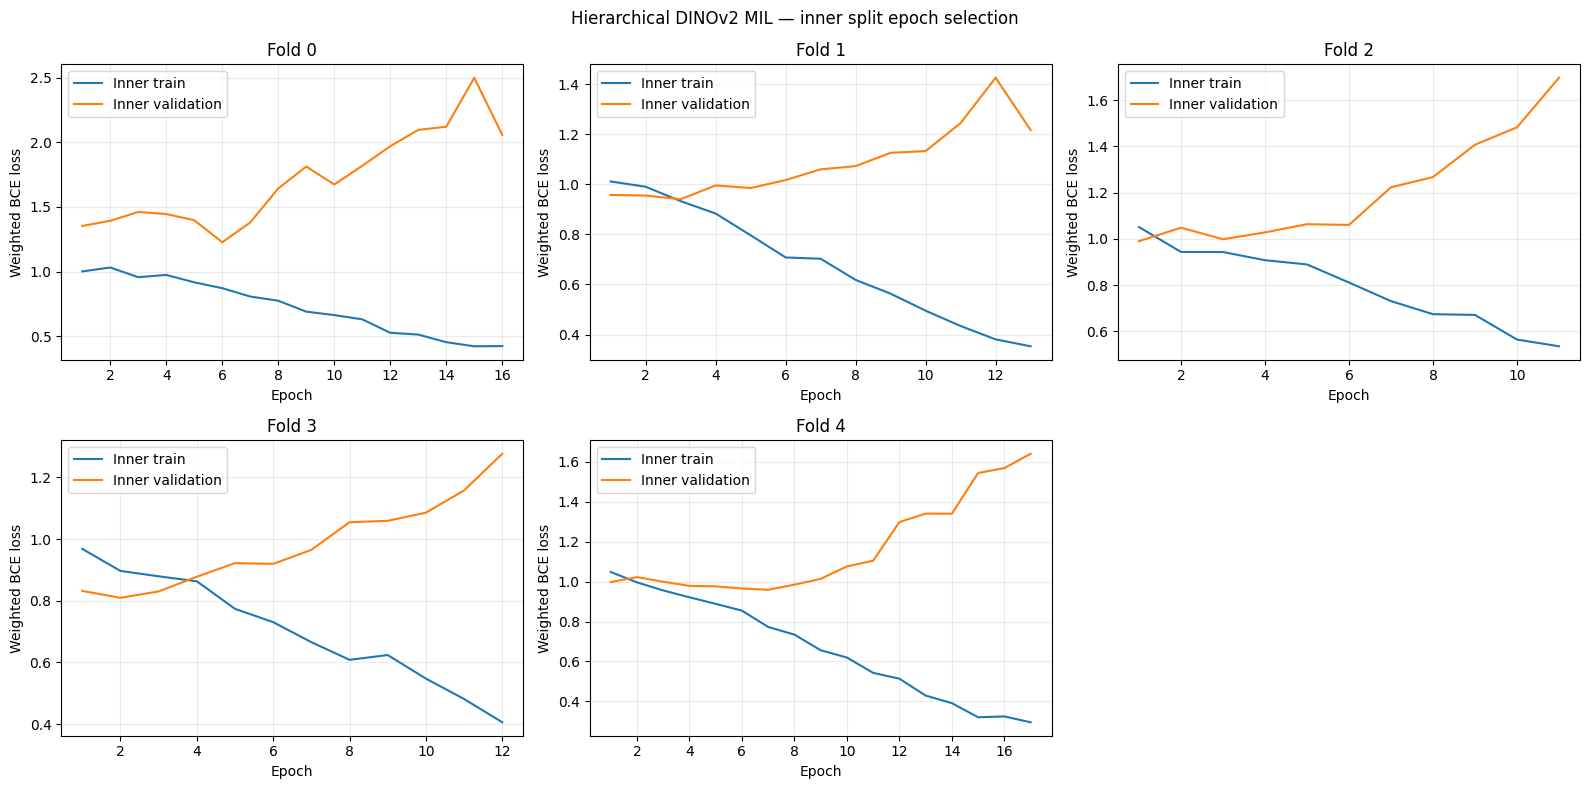

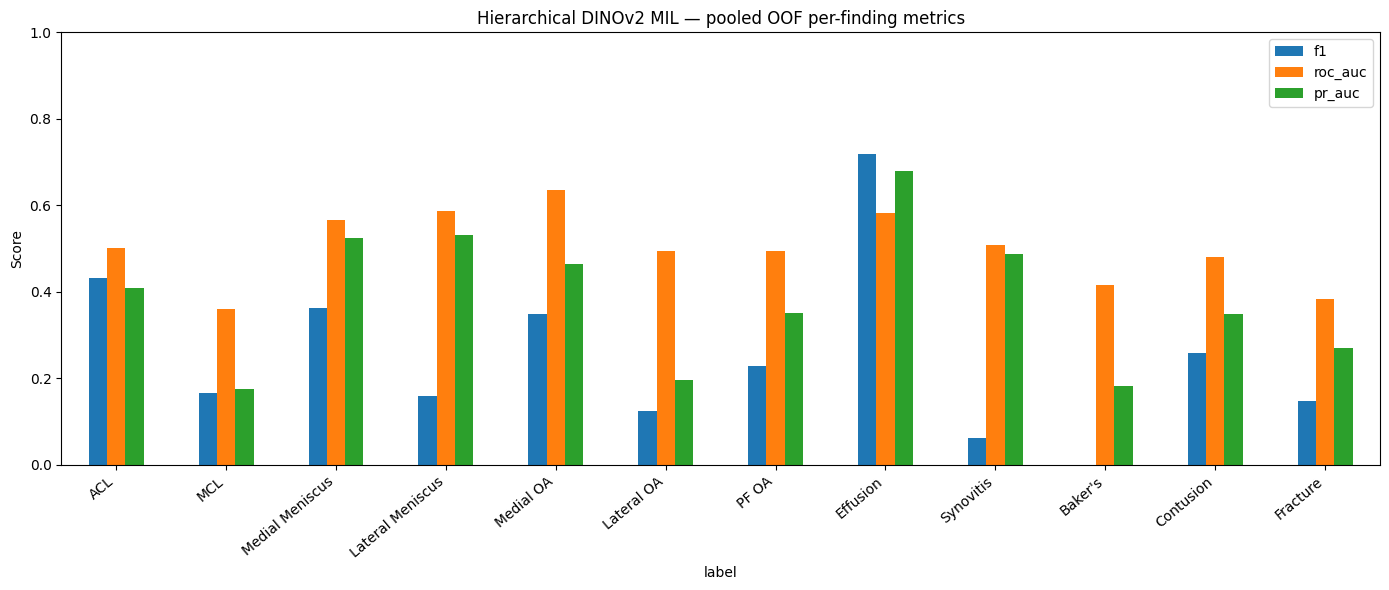


NOTEBOOK 12 FINAL ARTIFACT CHECK
OK   fold_training_summary.csv
OK   oof_predictions.csv
OK   training_history.csv
OK   oof_slice_attention_weights.csv
OK   oof_series_attention_weights.csv
OK   pooled_oof_metrics.csv
OK   oof_per_finding_metrics.csv
OK   metric_summary.csv
OK   series_attention_diagnostics.csv
OK   slice_attention_diagnostics.csv
OK   hierarchical_dinov2_comparison_row.csv
OK   run_summary.json
OK   learning_curves.png
OK   per_finding_metrics.png
OK   hierarchical_dinov2_fold_0.pth
OK   hierarchical_dinov2_fold_1.pth
OK   hierarchical_dinov2_fold_2.pth
OK   hierarchical_dinov2_fold_3.pth
OK   hierarchical_dinov2_fold_4.pth

Output directory: /kaggle/working/12_proposed_model
Missing artifacts: []
Studies: 58 | Folds: 5
Series attention sums to 1: True
Slice attention sums to 1: True

NOTEBOOK 12 COMPLETED SUCCESSFULLY.
Note: attention weights are aggregation weights, not clinical explanations.


In [9]:
# Inner-split learning curves (outer held-out folds never choose epochs).
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for fold in range(N_FOLDS):
    g = history_df[history_df["fold"] == fold]
    axes[fold].plot(g["epoch"], g["train_loss"], label="Inner train")
    axes[fold].plot(g["epoch"], g["val_loss"], label="Inner validation")
    axes[fold].set_title(f"Fold {fold}")
    axes[fold].set_xlabel("Epoch")
    axes[fold].set_ylabel("Weighted BCE loss")
    axes[fold].grid(alpha=0.25)
    axes[fold].legend()
axes[-1].axis("off")
fig.suptitle("Hierarchical DINOv2 MIL — inner split epoch selection")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

# Per-finding pooled OOF metrics.
plot_df = per_finding_df.set_index("label")[["f1", "roc_auc", "pr_auc"]]
ax = plot_df.plot(kind="bar", figsize=(14, 6))
ax.set_ylim(0, 1)
ax.set_title("Hierarchical DINOv2 MIL — pooled OOF per-finding metrics")
ax.set_ylabel("Score")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/per_finding_metrics.png", dpi=160, bbox_inches="tight")
plt.show()

comparison_row = {
    "model": "DINOv2 ViT-S/14 + hierarchical slice/series attention MIL",
    **{k: float(fold_results_df[k].mean()) for k in [
        "macro_auc", "macro_pr_auc", "macro_precision", "macro_recall",
        "macro_f1", "macro_specificity", "micro_f1", "hamming_loss", "subset_accuracy"
    ]},
    "n_gold_studies": int(len(oof_df)),
    "n_series": int(series_attention_df[["StudyInstanceUID", "SeriesInstanceUID"]].drop_duplicates().shape[0]),
    "n_2p5d_instances": int(len(slice_attention_df)),
    "n_folds": N_FOLDS,
    "threshold": CLASSIFICATION_THRESHOLD,
}
pd.DataFrame([comparison_row]).to_csv(f"{OUTPUT_DIR}/hierarchical_dinov2_comparison_row.csv", index=False)

run_summary = {
    "model": "Hierarchical DINOv2 + gated slice attention + gated series attention",
    "device": str(DEVICE),
    "n_gold_studies": int(len(oof_df)),
    "n_embeddings": int(len(metadata)),
    "embedding_dim": EMBED_DIM,
    "n_series": int(total_series),
    "n_folds": N_FOLDS,
    "threshold": CLASSIFICATION_THRESHOLD,
    "epochs_max": EPOCHS,
    "patience": PATIENCE,
    "evaluation": "inner split epoch selection; refit on full outer train; outer held-out OOF",
    "supervision": "gold labels only; no report pseudo-labels",
    "labels": LABEL_COLS,
    "pooled_oof_metrics": {k: (float(v) if np.isfinite(v) else None) for k, v in pooled_metrics.items()},
}
with open(f"{OUTPUT_DIR}/run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_summary, f, indent=2)

expected_outputs = [
    "fold_training_summary.csv", "oof_predictions.csv", "training_history.csv",
    "oof_slice_attention_weights.csv", "oof_series_attention_weights.csv",
    "pooled_oof_metrics.csv", "oof_per_finding_metrics.csv", "metric_summary.csv",
    "series_attention_diagnostics.csv", "slice_attention_diagnostics.csv",
    "hierarchical_dinov2_comparison_row.csv", "run_summary.json",
    "learning_curves.png", "per_finding_metrics.png",
]
expected_outputs += [f"hierarchical_dinov2_fold_{f}.pth" for f in range(N_FOLDS)]

print("\nNOTEBOOK 12 FINAL ARTIFACT CHECK")
missing = []
for name in expected_outputs:
    exists = os.path.exists(os.path.join(OUTPUT_DIR, name))
    print(("OK   " if exists else "MISS ") + name)
    if not exists:
        missing.append(name)

print("\nOutput directory:", OUTPUT_DIR)
print("Missing artifacts:", missing)
print("Studies:", len(oof_df), "| Folds:", fold_results_df["fold"].nunique())
print("Series attention sums to 1:", bool(np.allclose(series_sums.to_numpy(), 1.0, atol=1e-4)))
print("Slice attention sums to 1:", bool(np.allclose(slice_sums.to_numpy(), 1.0, atol=1e-4)))
if missing:
    raise RuntimeError("Notebook 12 finished with missing artifacts: " + ", ".join(missing))
print("\nNOTEBOOK 12 COMPLETED SUCCESSFULLY.")
print("Note: attention weights are aggregation weights, not clinical explanations.")